# Deconvolving the BBH Merger Rate
This notebook uses the LVK BBH merger rate data to compute the formation rate of BBH progenitors assuming delay time distributions (or vice versa).

# Initialization

Import packages, set time grids, and define functions.

In [ ]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import matplotlib.lines as mlines
from astropy.cosmology import Planck18, z_at_value
from astropy import units as u

from scipy.stats import linregress
from scipy.interpolate import interp1d
from scipy.signal import windows

from jax import random
from jax import config
import jax.numpy as jnp
import jax

config.update("jax_enable_x64", True)

import seaborn as sns
sns.set_context('paper', font_scale = 1.5)
sns.set_palette('colorblind')
sns.set_style({'font.family':'serif', 'font.serif':'Times New Roman'})

/Users/aryannaschiebelbein/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
# Time Grids
age = np.linspace(0,Planck18.age(1e-8).value,1000)*u.Gyr  # array of time in the age of the universe [Gyr]
redshift = z_at_value(Planck18.age,age,zmax=10000, zmin=1e-12) # array of time in redshift

tdmin = 10e6 #the minimum time delay: 10 million years [years]
tmax =  Planck18.age(1e-8).value*1e9  # tmax: the age of the universe [years]

times = np.linspace(tdmin,  tmax, 1000) #array of time delays considered

/Users/aryannaschiebelbein/anaconda3/lib/python3.11/site-packages/scipy/optimize/_optimize.py:2489: RuntimeWarning: overflow encountered in scalar multiply
  p = (x - v) * tmp2 - (x - w) * tmp1
/Users/aryannaschiebelbein/anaconda3/lib/python3.11/site-packages/scipy/optimize/_optimize.py:2497: RuntimeWarning: overflow encountered in scalar multiply
  if ((p > tmp2 * (a - x)) and (p < tmp2 * (b - x)) and


In [3]:
def deconvolve(data_times, mergerrate, timedelay, times, lambda_strength=1e-3, past='zero', pastmergerrate=0):
    """
    Deconvolve the merger rate to get the formation rate using Wiener deconvolution.
    Parameters:
        data_times: array
            Time points corresponding to the merger rate data.
        mergerrate: array
            Merger rate values at the given time points.
        timedelay: array
            Time delay kernel (e.g., ptau_neg1).
        times: array
            Time points corresponding to the desired formation rate output.
        lambda_strength: float
            Regularization strength for the Wiener filter (not used by default).
        past: string
            Setting for assumption of the merger rate beyond the LVK detection horizon. 'zero' assumes no mergers beyond what we can hear, 'constant' uses a value specified by pastmergerrate
        pastmergerrate: float
            Value for the merger rate beyond z=1.5
    Returns:
        formationrate: array
            Deconvolved formation rate corresponding to the input merger rate. 
    """
    N = len(times)
    N_pad = 2 * N - 1
    dt = times[1] - times[0]
    
    mergerrate_interp = interp1d(data_times, mergerrate, kind='linear', 
                                 bounds_error=False, fill_value="extrapolate") # extrapolate, so we can window the rate to prevent fft noise and preserve the data up to z=1.5 later on
    Rm_grid = np.array(mergerrate_interp(times))

    # the redshift zones we want to smooth over, to prevent noise during the fft but maximize the merger rate signal utilized
    t_150 = Planck18.age(1.5).to_value(u.yr)   # where our data ends
    t_155 = Planck18.age(1.55).to_value(u.yr)  # how quickly we want the extrapolation to go to zero
    t_010 = Planck18.age(0.1).to_value(u.yr)   # local universe tapering, to prevent fft noise
    
    high_z_mask = (times >= t_155) & (times <= t_150)
    N_high = np.sum(high_z_mask)
    
    if past == 'zero': # zero mergers beyond z=1.5
        final_window = np.ones(N)
        final_window[times < t_155] = 0
        if N_high > 0:
            final_window[high_z_mask] = windows.tukey(N_high * 2, alpha=1)[:N_high]
        Rm_grid_high_z = Rm_grid * final_window
        
    elif past == 'constant':
        # transition from Rm_grid to pastmergerrate
        Rm_grid_high_z = Rm_grid.copy()
        Rm_grid_high_z[times < t_155] = pastmergerrate
        
        if N_high > 0:
            # Create a 0 to 1 ramp over the transition zone
            ramp = windows.tukey(N_high * 2, alpha=1)[:N_high] 
            Rm_grid_high_z[high_z_mask] = (1 - ramp) * pastmergerrate + ramp * Rm_grid[high_z_mask]
        
        #bring the padding back down to zero, to prevent wrap-around errors because of fourier periodicity
        taper_len = int(N * 0.05) 
        if taper_len > 0:
            # We use the first half of a Tukey window to go from 0 up to 1
            edge_taper = windows.tukey(taper_len * 2, alpha=1)[:taper_len]
            Rm_grid_high_z[:taper_len] *= edge_taper
    else:
        Rm_grid_high_z = Rm_grid

    low_z_mask = (times >= t_010)
    N_low = np.sum(low_z_mask)
    if N_low > 0:
        Rm_grid_high_z[low_z_mask] *= windows.tukey(N_low * 2, alpha=0.1)[N_low:]

    Rm_grid_windowed = Rm_grid_high_z

    # deconvolution
    timedelay_fft = jnp.fft.rfft(timedelay, n=N_pad)
    ptau_power = jnp.abs(timedelay_fft)**2 # power spectrum of time delay kernel
    reg = lambda_strength * jnp.max(ptau_power + 1e-60) # regularization parameter, small constant to prevent division by zero, scales with power of time delay
    wiener_filter = jnp.conj(timedelay_fft) / (ptau_power + reg) 

    mergerrate_fft = jnp.fft.rfft(Rm_grid_windowed, n=N_pad)
    formationrate_padded = jnp.fft.irfft(mergerrate_fft * wiener_filter)
    formationrate = formationrate_padded[:N] / dt

    return formationrate#, Rm_grid_windowed

def ptau(taus, tmin=10,tmax = tmax*1e3, alpha=-2):
    """
    The power-law delay time distribution of when a star forms to when it participates in a BBH merger. 

    Parameters: 
        taus: array
            delay times in Myr
        tmin: float
            minimum delay time possible (default is 10 Myr)
        tmax: float
            maximum delay time possible (default is age of universe in Myr)
    Returns:
        p(tau): float
            probability that a system has the delay time tau
            
    """
    return  jnp.where((taus >= tmin) & (taus <= tmax), (alpha + 1) * (taus)**alpha/(tmax**(alpha + 1) - tmin**(alpha + 1)), 0)

def ptau_neg1(taus, tmin=10,tmax = tmax*1e3, alpha=-1):
    """
    The power-law delay time distribution of when a star forms to when it participates in a BBH merger, when the index is -1. 

    Parameters: 
        taus: array
            delay times in Myr
        tmin: float
            minimum delay time possible (default is 10 Myr)
        tmax: float
            maximum delay time possible (default is age of universe in Myr)
    Returns:
        p(tau): float
            probability that a system has the delay time tau
            
    """
    ptau_grid = jnp.where((taus >= tmin) & (taus <= tmax), taus**-1/(jnp.log(tmax) - jnp.log(tmin)), 0)
    return ptau_grid  

def form_rate(times, a, b, c):
    """
    The formation rate of BBH progenitors as a function of time. Same functional form as Katsianis et al. (2017)

    Parameters:
        times: array
            time in years
        a: float
            normalization constant
        b: float
            power law index
        c: float
            exponential decay constant
    Returns:
        formation rate: array
            formation rate at time t
     """
    SFR = a*(times/1e9) ** b * np.exp(c*times/1e9)
    
    # make SFR 0 when t<0
    SFR = jnp.where(times<0, 0, SFR)

    return(SFR)

# Data

Read in LVK GWTC-4.0 merger rates and COMPAS delay time distributions.

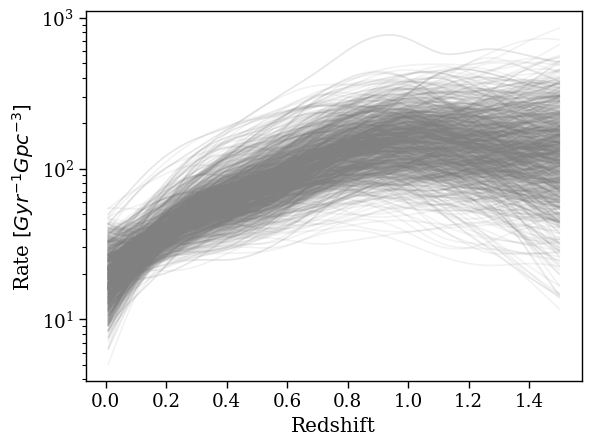

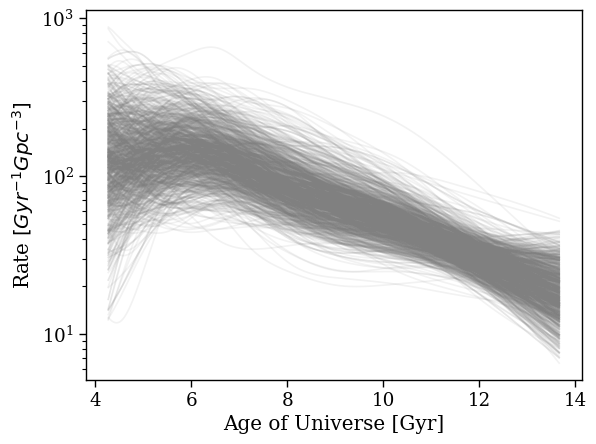

In [4]:
### read in O4 merger rate data ###
O4 = h5py.File("Rates_redshift_O4_bspline.h5","r")
zs_O4 = O4['zs'][:]
rates_O4 = O4['R_zs'][:]

# Plot vs. redshift
for i in np.random.randint(0, rates_O4.shape[1], size=1000):  
    plt.plot(zs_O4, rates_O4[:, i], color='gray', alpha=0.1)  
plt.yscale('log')
plt.xlabel('Redshift')
plt.ylabel('Rate $[Gyr^{-1}Gpc^{-3}]$')
plt.show()

# Plot vs. time
times_O4 = Planck18.age(zs_O4).value * 1e9
for i in np.random.randint(0, rates_O4.shape[1], size=1000):  
    plt.plot(times_O4/1e9, rates_O4[:, i], color='gray', alpha=0.1)
plt.yscale('log')
plt.xlabel('Age of Universe [Gyr]')
plt.ylabel('Rate $[Gyr^{-1}Gpc^{-3}]$')
plt.show()

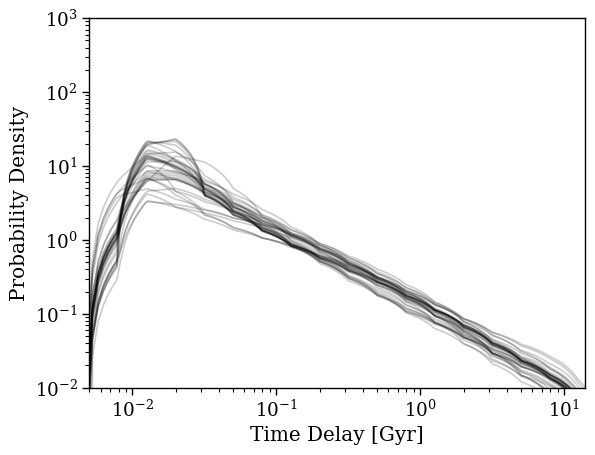

In [5]:
# COMPAS time delays: from https://zenodo.org/records/10019887

COMPAS_location = '10019887/Output'
all_files = os.listdir(COMPAS_location)
csv_files = [f for f in all_files if f.startswith('histogram_data_') and f.endswith('.csv')]

# Dictionary to store the (time_grid, delay time distribution) pairs
simulation_data = {}

for filename in csv_files:
    file_path = os.path.join(COMPAS_location, filename)
    try:
        data = np.loadtxt(file_path, delimiter=',', skiprows=1)
        
        # Simulation raw times in Gyr
        t_sim_raw = 10**data[:, 0]
        dN_dlogt = data[:, 1]
        dN_dt_raw = dN_dlogt / (t_sim_raw * np.log(10))
        
        t_min, t_max = t_sim_raw.min(), t_sim_raw.max()
        times_sim = np.linspace(t_min, t_max, 100000) 
        
        interp_func = interp1d(t_sim_raw, dN_dt_raw,bounds_error=False, kind='linear',fill_value=( 0.0))
        kernel_linear = interp_func(times_sim)
        
        integral = np.trapz(kernel_linear, times_sim)
        if integral > 0:
            kernel_normalized = kernel_linear / integral
        else:
            kernel_normalized = kernel_linear
            
        simulation_data[filename] = (times_sim, kernel_normalized)
        
    except Exception as e:
        print(f"Error processing {filename}: {e}")

# plot simulation time delays
filename = csv_files[0]
sim_times, sim_kernel = simulation_data[filename]

for fname, (t_grid, kern) in simulation_data.items():
    plt.plot(t_grid, kern, alpha=0.2, color='black')

#plot p(tau) alpha = -1
#plt.plot(t_grid, ptau_neg1(t_grid, tmin = 0.01, tmax=13.8), ls='--', lw='3', color='mediumvioletred')

plt.xscale('log')
plt.yscale('log')
plt.xlim(5e-3, 14)
plt.ylim(1e-2, 1e3)
plt.xlabel('Time Delay [Gyr]')
plt.ylabel('Probability Density')
plt.show()

# Progenitor Formation Rate Calculations

In [6]:
# compute the compatibility of the COMPAS delay time distributions with the O4a data

failrate_mergers = np.zeros(len(rates_O4[0])) # inital array for saving the fraction of COMPAS delay time distributions each merger rate is compatible with
failrate_timedelays = np.zeros(len(simulation_data)) # vice versa

check_mask = (times > times_O4[-1]) & (times < Planck18.age(0.1).value * 1e9) # define range we check physicality over, z=0.1 -> 1.5

for i, (sim_name, (t_sim_gyr, ptau_total)) in enumerate(simulation_data.items()): #for each COMPAS simulation
    t_sim_yr = t_sim_gyr * 1e9
    ptau_sim_yr = ptau_total / 1e9
    interp_ptau = interp1d(t_sim_yr, ptau_sim_yr, bounds_error=False, fill_value=0.0)
    
    timedelay = interp_ptau(times)
    timedelay /= jnp.trapezoid(timedelay, times)
    
    current_sim_fails = 0
    num_mergers = len(rates_O4[0])
    
    for j in range(num_mergers): # for each LVK merger rate
        merger_rate = rates_O4[:, j]
        # Deconvolve using the dense grid
        formationrate = deconvolve(times_O4, merger_rate, timedelay, times)
        
        if np.any(formationrate[check_mask] < 0): 
            failrate_mergers[j] += 1
            current_sim_fails += 1

    failrate_timedelays[i] = (current_sim_fails / num_mergers) #* 100
    print(f"Simulation {i} ({sim_name}): Failure Rate = {failrate_timedelays[i]:.2f}")

failrate_mergers = (failrate_mergers / len(simulation_data)) #* 100
print("-" * 30)
print("Processing Complete.")

Simulation 0 (histogram_data_faccFIXEDbeta0.5zetaHG5.5RemMassFRYER2012SNDELAYED_LOG.csv): Failure Rate = 0.17
Simulation 1 (histogram_data_faccFIXEDbeta0.5gammaMIXTUREfcircum0.25zetaHG6.0RemMassFRYER2012SNDELAYED_LOG.csv): Failure Rate = 0.40
Simulation 2 (histogram_data_faccFIXEDbeta0.5zetaHG6.0RemMassFRYER2022fmix0.5SNDELAYED_LOG.csv): Failure Rate = 0.23
Simulation 3 (histogram_data_faccTHERMALzetaHG6.5RemMassFRYER2012SNDELAYED_LOG.csv): Failure Rate = 0.12
Simulation 4 (histogram_data_faccFIXEDbeta0.5gammaMIXTUREfcircum0.375zetaHG6.0RemMassFRYER2012SNDELAYED_LOG.csv): Failure Rate = 0.01
Simulation 5 (histogram_data_faccFIXEDbeta0.5gammaMIXTUREfcircum0.0zetaHG6.0RemMassFRYER2012SNDELAYED_LOG.csv): Failure Rate = 0.19
Simulation 6 (histogram_data_fWR1.0coolWind1.0_LOG.csv): Failure Rate = 0.37
Simulation 7 (histogram_data_faccFIXEDbeta0.5zetaHG3.5RemMassFRYER2012SNDELAYED_LOG.csv): Failure Rate = 0.02
Simulation 8 (histogram_data_faccFIXEDbeta0.5fcore1.2zetaHG6.0RemMassFRYER2012SNDE

In [7]:
# for each time delay distirbution, what is the power-law alpha fit to it

# for each time delay distirbution, what is the power-law alpha fit to it, and what is the failure/pass rate
def fit_slope_with_intercept(t, k):
    try:
        mask = (t >= 0) & (t <= 10) & (k > 1e-6)
        if np.sum(mask) < 5: 
            return np.nan, np.nan
        log_t = np.log10(t[mask])
        log_k = np.log10(k[mask])
        slope, _, _,_, _ = linregress(log_t, log_k)
        return slope
    except:
        return np.nan

timedelay_alphas = np.zeros(len(simulation_data))

for i, (sim_name, (t_grid, ptau_total)) in enumerate(simulation_data.items()):
    alpha = fit_slope_with_intercept(t_grid, ptau_total)
    timedelay_alphas[i] = alpha

In [8]:
# pure power-law time delay failure rates

alpha_grid = np.linspace(-1.5, -0.5, 10) 
constants = [ 100, 200, 300, 400, 500]

# Storage for the final failure rate at each alpha
alpha_failure_rates = []
alpha_failure_rates_constants = {c: [] for c in constants}

print(f"{'Alpha':<10} | {'Failure Rate (%)':<15}")
print("-" * 50)

for a in alpha_grid:

    kernel_raw = ptau(times, tmin=tdmin, tmax=tmax , alpha=a)

    timedelay = kernel_raw / np.trapz(kernel_raw, times)
    
    failed_count = 0
    failed_counts_constants = {c: 0 for c in constants}

    num_mergers = rates_O4.shape[1]
    
    for j in range(num_mergers):
        merger_rate = rates_O4[:, j]
        
        formation_rate = deconvolve(times_O4, merger_rate, timedelay, times)
        
        if np.any(formation_rate[check_mask] < 0):
            failed_count += 1
        
        for c in constants:
            formation_rate_c = deconvolve(times_O4, merger_rate, timedelay, times, past = 'constant', pastmergerrate = c)
            if np.any(formation_rate_c[check_mask] < 0):
                failed_counts_constants[c] += 1

    fail_pct = (failed_count / num_mergers) 
    alpha_failure_rates.append(fail_pct)

    for c in constants:
        alpha_failure_rates_constants[c].append((failed_counts_constants[c] / num_mergers))
    
    print(f"{a:>10.2f} | {fail_pct:>14.2f}")

Alpha      | Failure Rate (%)
--------------------------------------------------
     -1.50 |           0.00
     -1.39 |           0.00
     -1.28 |           0.00
     -1.17 |           0.00
     -1.06 |           0.07
     -0.94 |           0.32
     -0.83 |           0.66
     -0.72 |           0.90
     -0.61 |           0.98
     -0.50 |           1.00


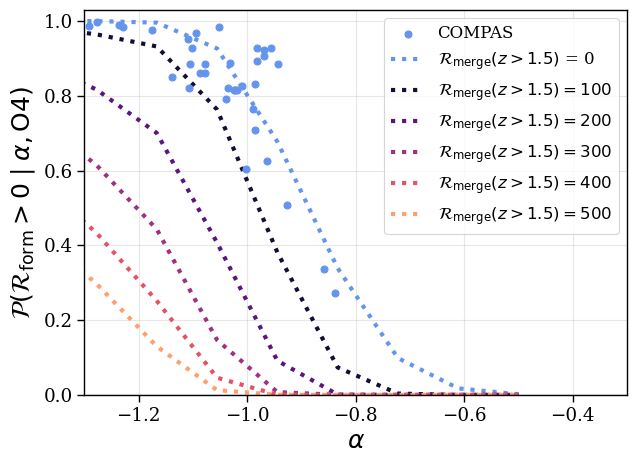

Assumption           | 95% Agreement (Safe) | 5% Agreement (Excluded)
-----------------------------------------------------------------
R(z>1.5) = 0         | alpha >=           -1.09 | alpha <=           -0.66
R(z>1.5) = 100       | alpha >=           -1.23 | alpha <=           -0.80
R(z>1.5) = 200       | alpha >=           -1.53 | alpha <=           -0.89
R(z>1.5) = 300       | alpha >=           -1.62 | alpha <=           -0.98
R(z>1.5) = 400       | alpha >=           -1.68 | alpha <=           -1.06
R(z>1.5) = 500       | alpha >=           -1.77 | alpha <=           -1.09


In [9]:
# Plot the COMPAS and power-law delay time compatibility with GW data

plt.figure(figsize=(7, 5))

# Plot the different constant assumptions
color_range = np.linspace(0.1, 0.8, len(constants))
colors = plt.cm.magma(color_range)
plt.scatter(timedelay_alphas, 1-failrate_timedelays, color = 'cornflowerblue',s=25, zorder=10,label=r'COMPAS')
plt.plot(alpha_grid, 1-np.array(alpha_failure_rates), color='cornflowerblue', linestyle=':', lw=3,  label=r'$\mathcal{R}_{\mathrm{merge}}(z>1.5)$ = 0')
for i, c in enumerate(constants):
    plt.plot(alpha_grid, 1-np.array(alpha_failure_rates_constants[c]), color=colors[i], linestyle=':', lw=3, label=fr'$\mathcal{{R}}_{{\mathrm{{merge}}}}(z>1.5) = {c}$')

plt.axhline(0, color='black', lw=1, alpha=0.3)
plt.xlabel(r'$\alpha$', fontsize=18)
plt.ylabel(r'$\mathcal{P}(\mathcal{R}_{\mathrm{form}}>0 \mid \alpha,\mathrm{O4})$', fontsize=18)
plt.grid(alpha=0.3)
plt.ylim(0,1.03)
plt.xlim(-1.3, -0.3)
plt.legend(loc='upper right', fontsize='small', ncol=1)
plt.savefig('passrate_vs_alpha.png', dpi=300, bbox_inches='tight')
plt.show()

# calculate the alpha thresholds for 95% and 5% compatibility

def find_alpha_threshold(alphas, pass_rates, threshold):
    sort_idx = np.argsort(pass_rates)
    x_interp = pass_rates[sort_idx]
    y_interp = alphas[sort_idx]
    
    # Use 'extrapolate' to handle cases where the data barely misses the threshold
    f = interp1d(x_interp, y_interp, bounds_error=False, fill_value="extrapolate")
    return float(f(threshold))

intervals = {}

pass_rates_zero = 1 - np.array(alpha_failure_rates)
a95_zero = find_alpha_threshold(alpha_grid, pass_rates_zero, 0.95)
a05_zero = find_alpha_threshold(alpha_grid, pass_rates_zero, 0.05)
intervals['zero'] = (a95_zero, a05_zero)

for c in constants:
    p_rates = 1 - np.array(alpha_failure_rates_constants[c])
    a95 = find_alpha_threshold(alpha_grid, p_rates, 0.95)
    a05 = find_alpha_threshold(alpha_grid, p_rates, 0.05)
    intervals[c] = (a95, a05)

print(f"{'Assumption':<20} | {'95% Agreement (Safe)':<20} | {'5% Agreement (Excluded)':<20}")
print("-" * 65)
for case, (high, low) in intervals.items():
    label = f"R(z>1.5) = {case}" if case != 'zero' else "R(z>1.5) = 0"
    print(f"{label:<20} | alpha >= {high:>15.2f} | alpha <= {low:>15.2f}")

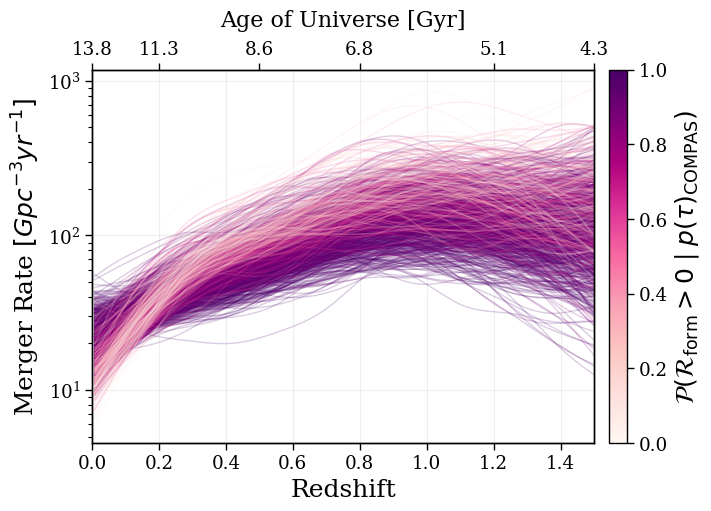

In [10]:
# plot the GWTC-4.0 merger rates coloured by COMPAS compatibility

pass_rates = 1 - failrate_mergers 
cmap = cm.RdPu 
norm = mcolors.Normalize(vmin=pass_rates.min(), vmax=pass_rates.max())

sample_size = 1000
random_indices = np.random.choice(np.arange(rates_O4.shape[1]), size=sample_size, replace=False)
sorted_indices = random_indices[np.argsort(pass_rates[random_indices])[::-1]]

fig, ax1 = plt.subplots(figsize=(7, 5), constrained_layout=True)

for i in sorted_indices:
    line_color = cmap(norm(pass_rates[i]))
    ax1.plot(zs_O4, rates_O4[:, i], color=line_color, alpha=0.2, lw=1)

ax2 = ax1.twiny()
z_ticks = np.array([0, 0.2, 0.5, 0.8, 1.2, 1.5])
age_ticks = Planck18.age(z_ticks).to_value(u.Gyr)

ax2.set_xlim(0, 1.5) 
ax2.set_xticks(z_ticks)
ax2.set_xticklabels([f'{a:.1f}' for a in age_ticks])
ax2.set_xlabel('Age of Universe [Gyr]', fontsize=16, labelpad=10)

sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax1, shrink=1, pad=0.00)
cbar.set_label(r'$\mathcal{P}(\mathcal{R}_{\mathrm{form}}>0 \mid p(\tau)_\mathrm{COMPAS})$', fontsize=18)

ax1.set_yscale('log')
ax1.set_xlim(0, 1.5)
ax1.set_xlabel('Redshift', fontsize=18)
ax1.set_ylabel(r'Merger Rate $[Gpc^{-3} yr^{-1}]$', fontsize=18)
ax1.grid(alpha=0.2)
plt.savefig('merger_rates.png', dpi=300, bbox_inches = 'tight')
plt.show()

In [11]:
# calculated the weighted perccentiles

def get_weighted_percentiles(data, weights, percentiles=[5, 50, 95]):
    
    ix = np.argsort(data)
    data_sorted = data[ix]
    weights_sorted = weights[ix]
    
    cum_weights = np.cumsum(weights_sorted)
    cum_weights /= cum_weights[-1] 
    
    return np.interp(np.array(percentiles)/100.0, cum_weights, data_sorted)


low_weighted = np.zeros(len(zs_O4))
med_weighted = np.zeros(len(zs_O4))
up_weighted  = np.zeros(len(zs_O4))

for i in range(len(zs_O4)):
    res = get_weighted_percentiles(rates_O4[i, :], pass_rates)
    low_weighted[i], med_weighted[i], up_weighted[i] = res

low_orig, med_orig, up_orig = np.percentile(rates_O4, [5, 50, 95], axis=1)

unweighted_indices = np.random.choice(np.arange(rates_O4.shape[1]), size=1000, replace=False)
rates_unweighted_subset = rates_O4[:, unweighted_indices]

w_norm = pass_rates / np.sum(pass_rates)
weighted_indices = np.random.choice(np.arange(rates_O4.shape[1]), size=1000, replace=True, p=w_norm)
rates_weighted_subset = rates_O4[:, weighted_indices]

target_zs = [0, 0.1, 0.2, 1.5]

print(f"{'Redshift':<10} | {'Original 90% CI':<30} | {'Weighted 90% CI':<30}")
print("-" * 75)

for tz in target_zs:
    idx = np.argmin(np.abs(zs_O4 - tz))
    actual_z = zs_O4[idx]
    
    orig_range = f"[{low_orig[idx]:.2f}, {up_orig[idx]:.2f}]"
    weight_range = f"[{low_weighted[idx]:.2f}, {up_weighted[idx]:.2f}]"
    
    print(f"{actual_z:<10.2f} | {orig_range:<30} | {weight_range:<30}")

Redshift   | Original 90% CI                | Weighted 90% CI               
---------------------------------------------------------------------------
0.01       | [10.23, 34.17]                 | [11.49, 35.05]                
0.10       | [18.69, 40.04]                 | [19.30, 40.36]                
0.20       | [27.27, 56.28]                 | [27.10, 54.97]                
1.50       | [38.61, 333.78]                | [36.52, 299.45]               


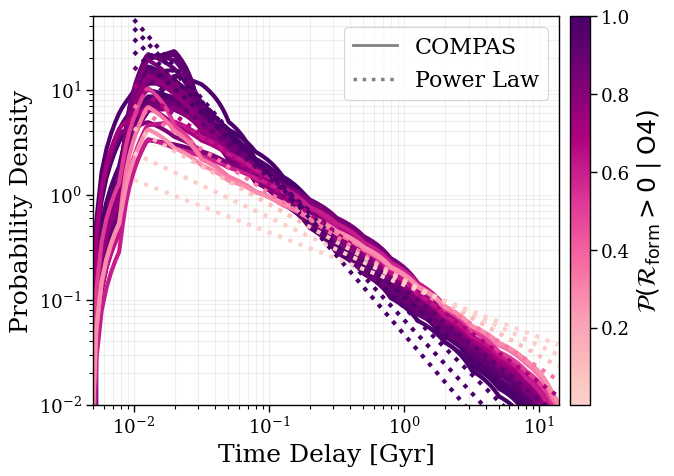

In [12]:
# plot the COMPAS and power-law delay times coloured on compatibility with GW data

pass_rates_td = 1 - failrate_timedelays
pass_rates_pl = 1 - np.array(alpha_failure_rates)


all_rates = np.concatenate([pass_rates_td, pass_rates_pl])

cmap_base = cm.RdPu
cmap = mcolors.LinearSegmentedColormap.from_list(
    'trunc_RdPu', cmap_base(np.linspace(0.2, 1.0))
)
norm = mcolors.Normalize(vmin=all_rates.min(), vmax=all_rates.max())

plt.figure(figsize=(7, 5))

file_indices = np.arange(len(csv_files))
sorted_indices = file_indices[np.argsort(pass_rates_td)[::-1]]

for idx in sorted_indices:
    fname = csv_files[idx]
    if fname in simulation_data:
        t_grid, kern = simulation_data[fname]
        line_color = cmap(norm(pass_rates_td[idx]))
        plt.plot(t_grid, kern, color=line_color, alpha=1, lw=3)

sorted_pl_indices = np.argsort(pass_rates_pl)[::-1]

for i in sorted_pl_indices:
    a = alpha_grid[i]

    times_gyr = times / 1e9

    kernel_raw = ptau(times, tmin=tdmin, tmax=tmax, alpha=a)

    timedelay_gyr = kernel_raw / np.trapz(kernel_raw, times_gyr)

    line_color = cmap(norm(pass_rates_pl[i]))
    plt.plot(times_gyr, timedelay_gyr, color=line_color, linestyle=':', alpha=1, lw=3)
    

sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=plt.gca(), pad=0.02)
cbar.set_label(r'$\mathcal{P}(\mathcal{R}_{\mathrm{form}}>0 \mid \mathrm{O4})$', fontsize=18)

compas_proxy = mlines.Line2D([], [], color='grey', linestyle='-', lw=2, label='COMPAS')
pl_proxy = mlines.Line2D([], [], color='grey', linestyle=':', lw=2.5, label='Power Law')

plt.xscale('log')
plt.yscale('log')
plt.xlim(5e-3, 14)
plt.ylim(1e-2, 5e1)
plt.xlabel('Time Delay [Gyr]', fontsize=18)
plt.ylabel('Probability Density', fontsize=18)
plt.grid(alpha=0.2, which='both')

plt.legend(handles=[compas_proxy, pl_proxy], fontsize=16, loc='upper right', frameon=True)

plt.tight_layout()
plt.savefig('ptau.png', dpi=300, bbox_inches='tight')
plt.show()

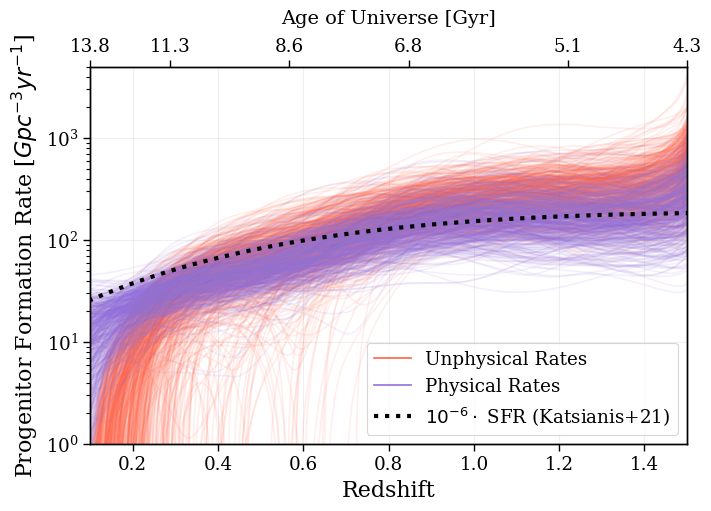

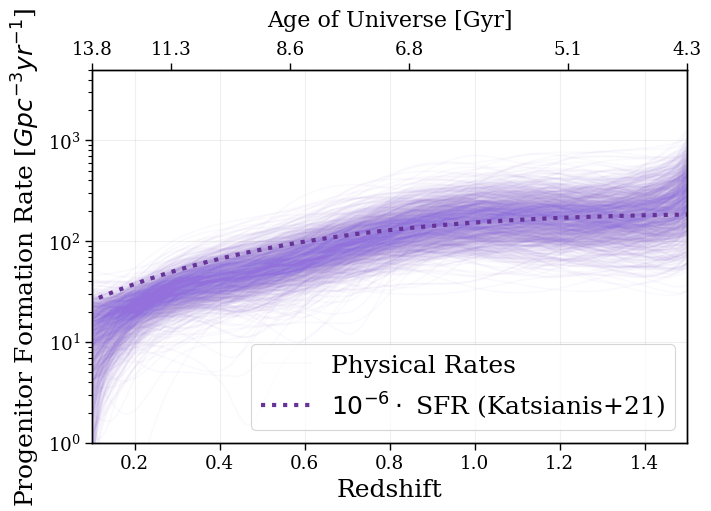

In [13]:
# plot the progenitor formation rates

# get age of universe <-> redshift conversion for plotting
z_ref_grid = np.linspace(0, 20, 5000)
ages_ref_grid = Planck18.age(z_ref_grid).to_value(u.yr)
age_to_z = interp1d(
    ages_ref_grid, 
    z_ref_grid, 
    kind='linear', 
    bounds_error=False, 
    fill_value="extrapolate"
)

z_grid = np.clip(age_to_z(times), 0, 20)
check_mask = (z_grid >= 0.1) & (z_grid <= 1.5)

physical_rates = []
unphysical_rates = []

sim_keys = list(simulation_data.keys())
num_merger_samples = rates_O4.shape[1]

# recomputing deconvolution to save formation rate arrays
while len(physical_rates) < 1000 or len(unphysical_rates) < 500:
    # randomly pick merger rate
    Rm_idx = np.random.randint(0, num_merger_samples - 1)
    merger_sample = rates_O4[:, Rm_idx]
    
    # randomly pick a time delay simulation
    s_key = np.random.choice(sim_keys)
    t_sim_gyr, ptau_total = simulation_data[s_key]
    
    t_sim_yr = t_sim_gyr * 1e9
    ptau_sim_yr = ptau_total / 1e9
    interp_ptau = interp1d(t_sim_yr, ptau_sim_yr, bounds_error=False, fill_value=0.0)
    td_curr = interp_ptau(times)
    td_curr /= jnp.trapezoid(td_curr, times)
    
    # deconvolve
    form_rate = deconvolve(times_O4, merger_sample, td_curr, times, past='zero')
    
    if np.any(form_rate[check_mask] < 0):
        if len(unphysical_rates) < 500:
            unphysical_rates.append(form_rate)
    else:
        if len(physical_rates) < 1000:
            physical_rates.append(form_rate)

# plotting

z_min, z_max = 0.1, 1.5
z_ticks = np.array([0, 0.2, 0.5, 0.8, 1.2, 1.5])
age_labels = [f"{Planck18.age(z).to_value(u.Gyr):.1f}" for z in z_ticks]

# physical and unphysical formation rates
plt.figure(figsize=(7, 5), constrained_layout=True)
ax1 = plt.gca()
ax1.set_xlim(z_min, z_max)
ax1.set_yscale('log')
ax1.set_ylim(1, 5e3)
ax1.set_xlabel('Redshift', fontsize=16)
ax1.set_ylabel(r'Progenitor Formation Rate [$Gpc^{-3} yr^{-1}$]', fontsize=16)
ax1.grid(alpha=0.2)

# axis for age of universe
ax2 = ax1.twiny()
ax2.set_xlim(z_min, z_max)
ax2.set_xticks(z_ticks)
ax2.set_xticklabels(age_labels)
ax2.set_xlabel('Age of Universe [Gyr]', fontsize=14, labelpad=10)

# plot 500 Unphysical
for i, rate in enumerate(unphysical_rates[:500]):
    label = 'Unphysical Rates' if i == 0 else ""
    ax1.plot(z_grid, rate, color='tomato', alpha=0.1, label=label)

# plot 500 Physical
for i, rate in enumerate(physical_rates[:500]):
    label = 'Physical Rates' if i == 0 else ""
    ax1.plot(z_grid, rate, color='mediumpurple', alpha=0.1, label=label)

#SFR
x_gyr = np.linspace(0.1, 13.7, 200)
sfr_katsianis = 0.1 * 1e-6 * (x_gyr)**1.83 * np.exp(-0.48 * x_gyr) * 1e9
z_sfr = np.clip(age_to_z(x_gyr * 1e9), 0, 20)

ax1.plot(z_sfr, sfr_katsianis, color='k', lw=3, ls=':', label=r'$10^{-6} \cdot$ SFR (Katsianis+21)')

# legend settings
handles, labels = ax1.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
leg1 = ax1.legend(by_label.values(), by_label.keys(), loc='lower right', frameon=True)
for lh in leg1.legend_handles: 
    lh.set_alpha(1.0)
plt.savefig('formationrates_withfails.png', dpi=300, bbox_inches = 'tight')
plt.show()

# physical formation rates only
plt.figure(figsize=(7, 5), constrained_layout=True)
ax_phys = plt.gca()
ax_phys.set_xlim(z_min, z_max)
ax_phys.set_yscale('log')
ax_phys.set_ylim(1, 5e3)
ax_phys.set_xlabel('Redshift', fontsize=18)
ax_phys.set_ylabel(r'Progenitor Formation Rate [$Gpc^{-3} yr^{-1}$]', fontsize=18)
ax_phys.grid(alpha=0.2)

# age of universe axis
ax_phys_2 = ax_phys.twiny()
ax_phys_2.set_xlim(z_min, z_max)
ax_phys_2.set_xticks(z_ticks)
ax_phys_2.set_xticklabels(age_labels)
ax_phys_2.set_xlabel('Age of Universe [Gyr]', fontsize=16, labelpad=10)

for i, rate in enumerate(physical_rates[:1000]):
    label = 'Physical Rates' if i == 0 else ""
    ax_phys.plot(z_grid, rate, color='mediumpurple', alpha=0.04, label=label)

ax_phys.plot(z_sfr, sfr_katsianis, color='rebeccapurple', lw=3, ls=':', label=r'$10^{-6} \cdot$ SFR (Katsianis+21)')

handles, labels = ax_phys.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax_phys.legend(by_label.values(), by_label.keys(), loc='lower right', frameon=True, fontsize=18)
plt.savefig('formationrates.png', dpi=300, bbox_inches = 'tight')
plt.show()

# $\kappa$ vs. $\alpha$

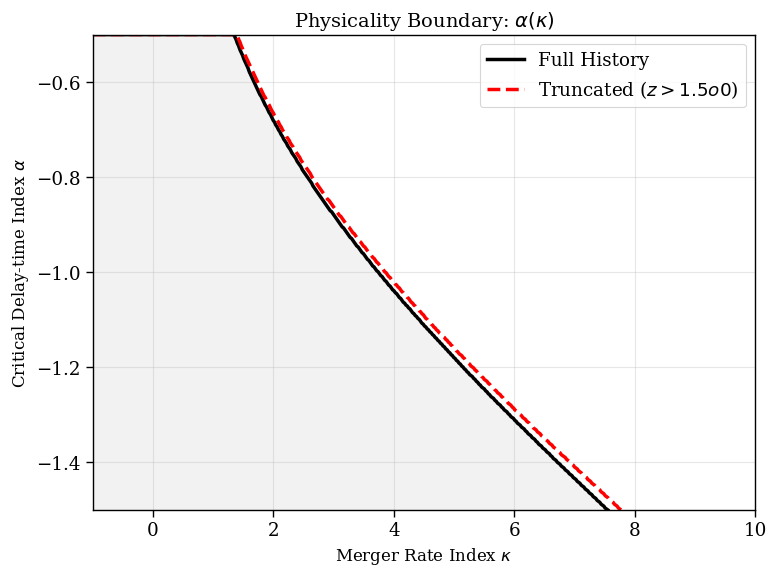

In [14]:
alpha_grid = np.linspace(-1.5, -0.5, 500)
kappa_grid = np.linspace(-1, 10, 500)

t_min = 10  # Myr
t_max = Planck18.age(0).to(u.Myr).value
times_myr = np.linspace(t_min, t_max, 1000)
times_yr = times_myr * 1e6

# build a fast lookup to get redshift from time
z_samps = np.linspace(0, 20, 200)
t_samps = Planck18.age(z_samps).to(u.Myr).value
get_z_from_t = interp1d(t_samps, z_samps, kind='cubic', fill_value="extrapolate")

zs_O4_matched = np.clip(get_z_from_t(times_O4 / 1e6), 0, None)

def get_boundary(truncate=False):
    pass_matrix = np.zeros((len(kappa_grid), len(alpha_grid)))
    
    for i, k in enumerate(kappa_grid):
        m_rate_O4 = (1 + zs_O4_matched)**k
        if truncate:
            # taper at z=1.5 to prevent FFT ringing
            taper = 1 / (1 + np.exp(10 * (zs_O4_matched - 1.5)))
            m_rate_O4 *= taper

        for j, a in enumerate(alpha_grid):
            kernel_raw = ptau(times_myr, tmin=t_min, tmax=t_max, alpha=a)
            td = kernel_raw / np.trapz(kernel_raw, times_yr)

            # times_O4 and m_rate_O4 are now guaranteed equal length
            f_rate = deconvolve(times_O4, m_rate_O4, td, times_yr)

            if not np.any(f_rate[check_mask] < 0):
                pass_matrix[i, j] = 1.0

    a_crit = np.full(len(kappa_grid), np.nan)
    for i in range(len(kappa_grid)):
        valid = pass_matrix[i, :] == 1
        if np.any(valid):
            a_crit[i] = alpha_grid[valid].max()
    return a_crit

alpha_crit_full = get_boundary(truncate=False)
alpha_crit_trunc = get_boundary(truncate=True)

plt.figure(figsize=(8, 6))
plt.plot(kappa_grid, alpha_crit_full, color='black', lw=2.5, label='Full History')
plt.plot(kappa_grid, alpha_crit_trunc, color='red', ls='--', lw=2.5, label='Truncated ($z > 1.5 \to 0$)')

plt.fill_between(kappa_grid, alpha_crit_full, alpha_grid.min(), color='gray', alpha=0.1)

plt.xlabel(r'Merger Rate Index $\kappa$', fontsize=12)
plt.ylabel(r'Critical Delay-time Index $\alpha$', fontsize=12)
plt.title(r'Physicality Boundary: $\alpha(\kappa)$', fontsize=14)
plt.xlim(kappa_grid.min(), kappa_grid.max())
plt.ylim(alpha_grid.min(), alpha_grid.max())
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

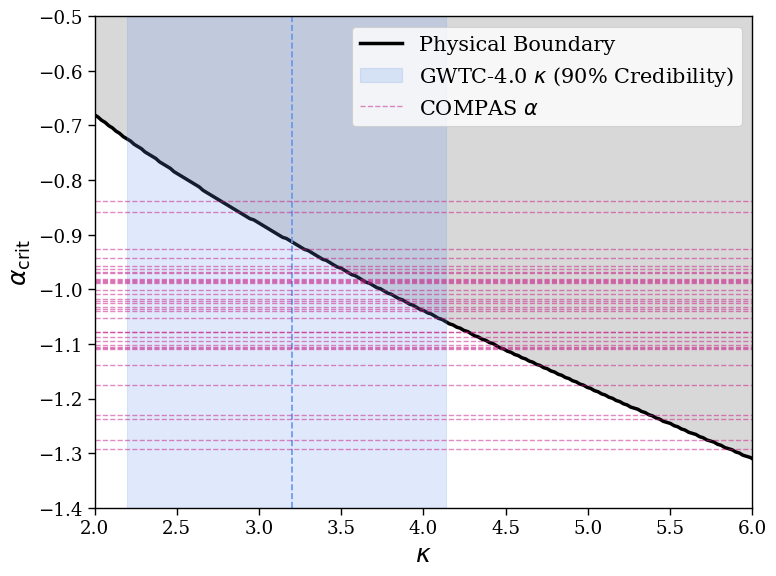

In [15]:
plt.figure(figsize=(8, 6))
plt.plot(kappa_grid, alpha_crit_full, color='black', lw=2.5, label='Physical Boundary')

plt.fill_between(kappa_grid, alpha_crit_full, alpha_grid.max(), color='gray', alpha=0.3)

k_min, k_max = 3.2 - 1.00, 3.2 + 0.94
plt.axvspan(k_min, k_max, color='cornflowerblue', alpha=0.2, label=r'GWTC-4.0 $\kappa$ (90% Credibility)', zorder=2)
plt.axvline(3.2, color='cornflowerblue', alpha=1, ls='--', zorder=2)


for i, val in enumerate(timedelay_alphas):
    lbl = r'COMPAS $\alpha$' if i == 0 else ""
    plt.axhline(val, color='mediumvioletred', linestyle='--', alpha=0.5, lw=1, label=lbl)

plt.xlabel(r'$\kappa$', fontsize=18)
plt.ylabel(r'$\alpha_\mathrm{crit}$', fontsize=18)

plt.xlim(2, 6)
plt.ylim(-1.4, -0.5)

plt.legend(loc='best', fontsize=15)
plt.tight_layout()
plt.savefig('alpha_v_kappa.png', dpi = 300, bbox_inches='tight')
plt.show()